<a href="https://colab.research.google.com/github/varshini-sharma/732224ai110/blob/main/cat_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Movie Review Sentiment Classification
Using the IMDB Dataset to classify reviews as positive or negative.

### Project Goals:
1. Use 5,000 reviews (approx. 2,500 positive and 2,500 negative).
2. Clean, tokenize, encode, and pad the review text.
3. Split the dataset into training, validation, and testing sets.
4. Train a sequential text classification model.
5. Evaluate accuracy, precision, recall, and F1-score.
6. Plot the confusion matrix and test on 5 unseen reviews.

Total reviews: 4960
sentiment
negative    2480
positive    2480
Name: count, dtype: int64

Training: 3472
Validation: 744
Testing: 744


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 200)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,306,945 (4.99 MB)

 Trainable params: 1,306,945 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 31s 243ms/step - accuracy: 0.5844 - loss: 0.6643 - val_accuracy: 0.7070 - val_loss: 0.6001
Epoch 2/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 40s 237ms/step - accuracy: 0.8096 - loss: 0.4569 - val_accuracy: 0.7621 - val_loss: 0.5231
Epoch 3/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 27s 247ms/step - accuracy: 0.9323 - loss: 0.1776 - val_accuracy: 0.8239 - val_loss: 0.4203
Epoch 4/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 26s 238ms/step - accuracy: 0.9847 - loss: 0.0570 - val_accuracy: 0.8172 - val_loss: 0.6589
Epoch 5/8
109/109 ━━━━━━━━━━━━━━━━━━━━ 41s 238ms/step - accuracy: 0.9965 - loss: 0.0153 - val_accuracy: 0.8185 - val_loss: 0.6641


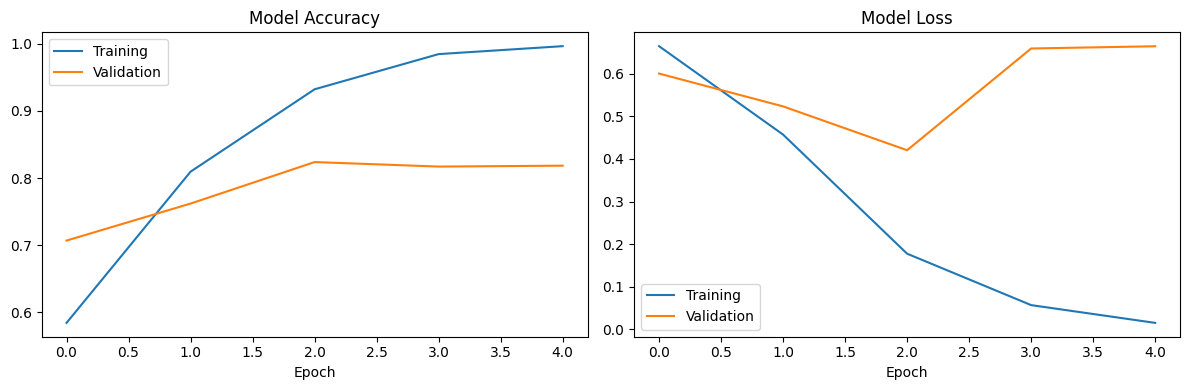


TEST PERFORMANCE
Accuracy : 0.8132
Precision: 0.8263
Recall   : 0.7930
F1 Score : 0.8093

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.83      0.82       372
    Positive       0.83      0.79      0.81       372

    accuracy                           0.81       744
   macro avg       0.81      0.81      0.81       744
weighted avg       0.81      0.81      0.81       744



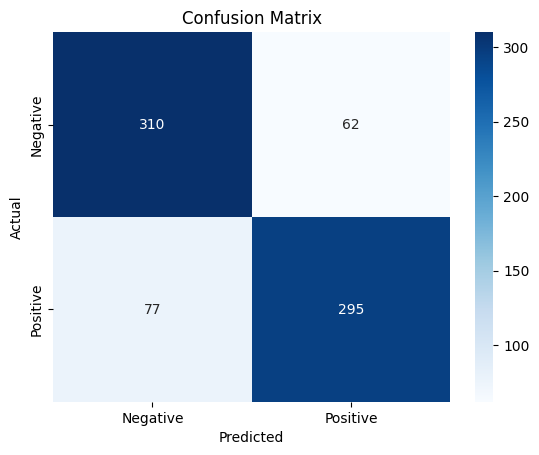


FIVE UNSEEN REVIEW PREDICTIONS

1. Review: This movie was fantastic and the acting was excellent.
   Sentiment: Positive
   Positive probability: 0.8803

2. Review: The film was boring and a complete waste of time.
   Sentiment: Negative
   Positive probability: 0.0292

3. Review: I loved the story and would happily watch it again.
   Sentiment: Positive
   Positive probability: 0.9114

4. Review: Terrible screenplay and disappointing performances.
   Sentiment: Negative
   Positive probability: 0.0432

5. Review: The movie was average but some scenes were enjoyable.
   Sentiment: Negative
   Positive probability: 0.4147


In [9]:

!pip -q install seaborn scikit-learn openpyxl

import re
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input, TextVectorization, Embedding,
    Bidirectional, LSTM, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

# 1. Load dataset (handle either CSV or Excel format)
uploaded_filename = "kaggledataset.xlsx"

if uploaded_filename.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(uploaded_filename)
else:
    df = pd.read_csv(uploaded_filename)

df.columns = df.columns.str.lower().str.strip()
df = df[['review', 'sentiment']].dropna()
df['sentiment'] = df['sentiment'].str.lower().str.strip()
df = df[df['sentiment'].isin(['positive', 'negative'])]
df = df.drop_duplicates(subset='review')

# 2. Select 2500 reviews from each class
counts = df['sentiment'].value_counts()
n = min(2500, int(counts.get('positive', 0)),
        int(counts.get('negative', 0)))

if n == 0:
    raise ValueError("Dataset must contain positive and negative reviews.")

df = pd.concat([
    df[df.sentiment == 'positive'].sample(n=n, random_state=42),
    df[df.sentiment == 'negative'].sample(n=n, random_state=42)
]).sample(frac=1, random_state=42).reset_index(drop=True)

print("Total reviews:", len(df))
print(df['sentiment'].value_counts())

# 3. Clean review text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-za-z\s]', ' ', text)  # Keep only lowercase letters and spaces
    return re.sub(r'\s+', ' ', text).strip()

df['review'] = df['review'].apply(clean_text)
df['label'] = df['sentiment'].map({'negative': 0, 'positive': 1})

X = df['review'].values
y = df['label'].values

# 4. Split into train, validation and test sets (70:15:15)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print("\nTraining:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

# 5. Tokenization, encoding and padding
max_words = 20000
max_length = 200

vectorizer = TextVectorization(
    max_tokens=max_words,
    output_mode='int',
    output_sequence_length=max_length
)
vectorizer.adapt(X_train)

# 6. Build Sequential model
model = Sequential([
    Input(shape=(), dtype=tf.string),
    vectorizer,
    Embedding(max_words, 64, mask_zero=True),
    Bidirectional(LSTM(32)),
    Dropout(0.5),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 7. Train model
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

# 8. Plot accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['accuracy'], label='Training')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Model Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Training')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Model Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

# 9. Test and evaluate
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("\nTEST PERFORMANCE")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1 Score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=['Negative', 'Positive'],
    zero_division=0
))

# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# 11. Predict five unseen reviews (use tf.constant with dtype=tf.string)
reviews = [
    "This movie was fantastic and the acting was excellent.",
    "The film was boring and a complete waste of time.",
    "I loved the story and would happily watch it again.",
    "Terrible screenplay and disappointing performances.",
    "The movie was average but some scenes were enjoyable."
]

predictions = model.predict(tf.constant(reviews, dtype=tf.string), verbose=0).ravel()

print("\nFIVE UNSEEN REVIEW PREDICTIONS")
for i, (review, score) in enumerate(zip(reviews, predictions), 1):
    label = "Positive" if score >= 0.5 else "Negative"
    print(f"\n{i}. Review: {review}")
    print(f"   Sentiment: {label}")
    print(f"   Positive probability: {score:.4f}")